# Практическое занятие №2. Обучение нейронных сетей

## Логистическая регрессия на датасете Heart Disease (Cleveland)

**Дисциплина:** Методы машинного обучения
**Кафедра:** Интеллектуальных информационных систем и кибербезопасности
**ВУЗ:** АНО ВО РОСНОУ
**Преподаватель:** Марков Артем Алексеевич
**Студент:** Галимский Дмитрий, группа 413м

---

## Постановка задачи

Требуется решить задачу **бинарной классификации**: по 13 клиническим
признакам пациента определить, есть ли у него ишемическая болезнь сердца.

Модель — **логистическая регрессия**. Выбор обоснован: целевая переменная
имеет два класса, признаки числовые и разнородные по масштабу, а сама задача
медицинская, где цена ошибки асимметрична — пропущенный больной опаснее
ошибочно направленного здорового.

Особенность данных, на которой строится вся работа: пропуски в этом датасете
**не помечены как NaN** — они записаны символом `?`. Наивная проверка
`isna()` их не увидит, и модель обучится на «битых» значениях. Сначала мы
найдём их поиском по всей таблице и только потом закроем.

После оценки — выводы, где разбирается, что получилось и почему.

По методичке работа разбита на четыре части, и ниже они идут именно
в таком порядке:

1. **Данные** — выбор датасета, разведка, приведение к машинному виду.
2. **Архитектура** — проектирование слоёв сети под тип данных.
3. **Обучение** — реализация цикла обучения.
4. **Оценка** — метрики качества и разбор ошибок.

После оценки — выводы, где разбирается, что получилось и почему.


In [1]:
# Ячейка 1 — зависимости.
#
# В Google Colab этот стек уже установлен, и команда ничего не скачивает.
# Локально она ставит недостающее, поэтому один и тот же ноутбук работает
# и в облаке, и на машине. Версии не фиксируем: pip подберёт совместимые.
%pip install -q torch torchvision numpy pandas scikit-learn matplotlib seaborn

# Проверяем, что всё действительно доступно, — иначе ошибка всплывёт
# не в этой ячейке, а где-нибудь в середине обучения.
import importlib

for _package in ("torch", "torchvision", "numpy", "pandas", "sklearn",
                 "matplotlib", "seaborn"):
    _module = importlib.import_module(_package)
    print(f"{_package:12s} {_module.__version__}")


Note: you may need to restart the kernel to use updated packages.


torch        2.14.0+cpu


torchvision  0.29.1+cpu
numpy        2.5.3


pandas       3.0.5


sklearn      1.9.1


matplotlib   3.11.2


seaborn      0.13.2


In [2]:
# Все импорты собраны в одной ячейке в самом верху файла — так их удобнее
# просматривать, и ниже по ноутбуку не остаётся «внезапно» появляющихся
# библиотек.

# Загрузка сырого CSV прямо из репозитория UCI: файл небольшой,
# и так видно, что данные приходят именно в том виде, в каком их отдали.
import io
import urllib.request

# Табличные операции: чтение, типы, сводные таблицы.
import pandas as pd

# Численные массивы и генерация сетки порогов для подбора порога.
import numpy as np

# Графики. pyplot — базовые графики, seaborn — аккуратные heatmap и boxplot.
import matplotlib.pyplot as plt
import seaborn as sns

# Модель, пайплайн «масштабирование + обучение» и базовая линия для сравнения.
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier

# Разделение выборок со стратификацией по цели — без неё доля класса
# в выборках «плавает», и оценка модели становится случайной.
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict

# Стандартизация: без неё признаки разного масштаба делают одни градиенты
# в сотни раз больше других, и метод плохо сходится.
from sklearn.preprocessing import StandardScaler

# Метрики качества, матрица ошибок и кривые для выбора порога.
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve, balanced_accuracy_score)

In [3]:
# Воспроизводимость: фиксируем генератор случайных чисел, иначе каждый
# запуск ноутбука давал бы немного разные разбиения и метрики.
SEED = 42
np.random.seed(SEED)

# Единый стиль оформления всех графиков ноутбука.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11
pd.set_option("display.max_columns", None)

## 1. Данные

**Heart Disease (Cleveland)** — открытый набор данных медицинской диагностики,
собранный в клинике Кливленда (США). В нём 303 наблюдения и 14 столбцов,
из которых 13 — признаки и один — целевая переменная.

| Столбец | Тип | Что означает |
|---|---|---|
| `age` | числовой | Возраст, лет |
| `sex` | категориальный | Пол: 1 — мужчина, 0 — женщина |
| `cp` | категориальный | Тип боли в груди (1–4, 4 — типичная стенокардия) |
| `trestbps` | числовой | Артериальное давление в покое, мм рт. ст. |
| `chol` | числовой | Уровень холестерина, мг/дл |
| `fbs` | категориальный | Сахар крови натощак выше нормы: 1 — да |
| `restecg` | категориальный | Тип ЭКГ в покое (0–2) |
| `thalach` | числовой | Максимальная ЧСС, уд/мин |
| `exang` | категориальный | Стенокардия при нагрузке: 1 — да |
| `oldpeak` | числовой | Депрессия ST-сегмента |
| `slope` | категориальный | Наклон пика нагрузочного теста (1–3) |
| `ca` | категориальный | Число магистральных сосудов, окрашенных рентгеном (0–3) |
| `thal` | категориальный | Результат теста с нагрузкой на кровяное давление (3, 6, 7) |
| `num` | целевая | Наличие болезни: 0 — нет, 1–4 — есть, число = степень тяжести |

Целевая переменная `num` — **порядковая, не бинарная**: нули означают
отсутствие болезни, а 1–4 — разную тяжесть. Для бинарной классификации
сводим её к одному признаку «болезнь есть / нет» (0 и всё, что больше нуля).

Почему этот датасет выбран:

* пропуски **закодированы символом `?`**, а не `NaN` — классическая ловушка,
  которую нужно уметь обнаружить вручную;
* классы почти сбалансированы, но **не идеально** — дисбаланс умеренный,
  из-за чего accuracy сама по себе обманывает;
* признаки приведены к **сильно разным масштабам** (возраст — десятки,
  `oldpeak` — доли), что делает стандартизацию обязательным шагом;
* задача медицинская, поэтому порог вероятности приходится выбирать
  осмысленно, а не по умолчанию 0.5.

In [4]:
DATASET_URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
               "heart-disease/processed.cleveland.data")

# Читаем файл БЕЗ параметра na_values: хотим увидеть данные ровно такими,
# какими они пришли, чтобы понять, чем выражены пропуски.
COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

response = urllib.request.urlopen(DATASET_URL, timeout=60)
raw_text = response.read().decode("utf-8")

# names= обязателен: в файле нет строки заголовка, иначе первая строка
# данных уехала бы в столбцы.
df = pd.read_csv(io.StringIO(raw_text), names=COLUMNS)

print(f"Скачано {len(raw_text)} символов, таблица {df.shape[0]} строк x {df.shape[1]} столбцов")
print("\nТипы столбцов после чтения:")
display(df.dtypes.to_frame("тип"))

Скачано 18461 символов, таблица 303 строк x 14 столбцов

Типы столбцов после чтения:


,тип
age,float64
sex,float64
cp,float64
trestbps,float64
chol,float64
fbs,float64
restecg,float64
thalach,float64
exang,float64
oldpeak,float64


## 2. Проверка и очистка данных

### 2.1 Ловушка пропусков

Посмотрим на типы столбцов выше: `ca` и `thal` имеют тип **string**, а не
числовой. Это уже сигнал: если бы пропусков не было, все 13 признаков были бы
числами. Проверим это напрямую.

df.isna().sum().sum() = 0  <- пропуски НЕ найдены
Найдено символов '?' во всей таблице: 6


,символов '?'
ca,4
thal,2


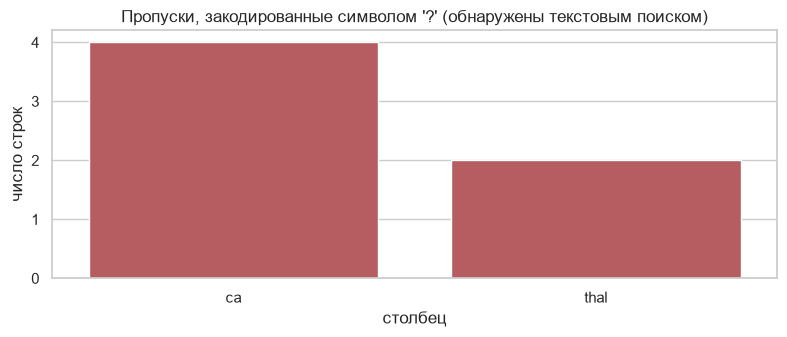

In [5]:
# Стандартная проверка пропусков показывает ноль: символ "?" — это строка,
# а не пропуск, поэтому pandas считает данные полными.
naive_missing = int(df.isna().sum().sum())
print(f"df.isna().sum().sum() = {naive_missing}  <- пропуски НЕ найдены")

# Ищем пропуски честно: сравниваем КАЖДОЕ значение каждого столбца со строкой "?".
# Так находятся пропуски независимо от того, как файл их закодировал.
missing_mask = df.apply(lambda column: column.astype(str).str.strip().eq("?"))
missing_by_column = missing_mask.sum()

print(f"Найдено символов '?' во всей таблице: {int(missing_by_column.sum())}")
display(missing_by_column[missing_by_column > 0].rename("символов '?'").to_frame())

fig, ax = plt.subplots(figsize=(8, 3.5))
# rename до reset_index: у серии нет имени, поэтому в reset_index её столбец
# называется "index" — под таким именем он и придёт в график.
missing_plot = missing_by_column[missing_by_column > 0].rename("пропусков").reset_index()
sns.barplot(data=missing_plot, x="index", y="пропусков", ax=ax, color="#C44E52")
ax.set_title("Пропуски, закодированные символом '?' (обнаружены текстовым поиском)")
ax.set_xlabel("столбец")
ax.set_ylabel("число строк")
plt.tight_layout()
plt.show()

### 2.2 Замена «?» на настоящий пропуск

Найденные места переводим в `NaN` — с этого момента стандартные инструменты
pandas работают с ними как с пропусками. Заодно возвращаем столбцам числовой
тип: `?` превратил их в строки, и арифметика с ними больше невозможна.

In [6]:
# where(маска, other=NaN) заменяет значения на True-месте и оставляет
# остальные нетронутыми — точечная правка без потери типов у соседних столбцов.
df = df.where(~missing_mask, other=np.nan)

# Столбцы, где была строковая смесь, возвращаем к числам.
for column in COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print(f"Пропусков после замены: {int(df.isna().sum().sum())}")
display(df.isna().sum()[df.isna().sum() > 0].rename("пропусков").to_frame())
display(df.head())

Пропусков после замены: 6


,пропусков
ca,4
thal,2


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### 2.3 Дубликаты

Даже если дубликатов нет, код их поиска обязателен: на других датасетах они
есть всегда, и молчаливые дубли перекосают обучение.

In [7]:
# Полные дубликаты — совпадают все столбцы, включая целевой.
full_duplicates = int(df.duplicated().sum())

# Дубликаты по признакам: те же показатели пациента, но разный диагноз —
# такие строки подозрительны сильнее всего.
feature_columns = [column for column in COLUMNS if column != "num"]
feature_duplicates = int(df.duplicated(subset=feature_columns).sum())

print(f"Полных дубликатов строк: {full_duplicates}")
print(f"Дубликатов по 13 признакам: {feature_duplicates}")
print("Вывод: датасет уже дедуплицирован, удалять нечего."
      if full_duplicates == 0 and feature_duplicates == 0
      else f"Вывод: полных дубликатов {full_duplicates}, по признакам {feature_duplicates}.")

Полных дубликатов строк: 0
Дубликатов по 13 признакам: 0
Вывод: датасет уже дедуплицирован, удалять нечего.


### 2.4 Заполнение пропусков

Разные типы признаков требуют разных стратегий, и это не формальность:

* **числовые** (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`) заполняем
  **медианой** — она устойчива к выбросам, в отличие от среднего;
* **категориальные** (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`,
  `ca`, `thal`) заполняем **модой** — самой частой категорией. Среднее по
  категориям не имеет смысла, а выдуманное значение породило бы
  несуществующую категорию.

In [8]:
NUMERIC_FEATURES = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CATEGORICAL_FEATURES = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

# Считаем статистики ДО заполнения: их нужно показать, а не молча применить.
fill_values = pd.DataFrame({
    "признак": NUMERIC_FEATURES + CATEGORICAL_FEATURES,
    "стратегия": ["медиана"] * len(NUMERIC_FEATURES) + ["мода"] * len(CATEGORICAL_FEATURES),
    "значение": list(df[NUMERIC_FEATURES].median()) + list(df[CATEGORICAL_FEATURES].mode().iloc[0]),
})
display(fill_values)

df[NUMERIC_FEATURES] = df[NUMERIC_FEATURES].fillna(df[NUMERIC_FEATURES].median())
df[CATEGORICAL_FEATURES] = df[CATEGORICAL_FEATURES].fillna(df[CATEGORICAL_FEATURES].mode().iloc[0])

missing_total = int(df.isna().sum().sum())
print(f"Итоговое число пропусков после очистки: {missing_total}")
print(f"Размер датасета после очистки: {df.shape[0]} строк x {df.shape[1]} столбцов")
print(f"Пропуски закрыты, ни одна строка не потеряна: {df.shape[0]} из 303")

assert missing_total == 0, "Очистка не доведена до конца" 

,признак,стратегия,значение
0,age,медиана,56.0
1,trestbps,медиана,130.0
2,chol,медиана,241.0
3,thalach,медиана,153.0
4,oldpeak,медиана,0.8
5,sex,мода,1.0
6,cp,мода,4.0
7,fbs,мода,0.0
8,restecg,мода,0.0
9,exang,мода,0.0


Итоговое число пропусков после очистки: 0


Размер датасета после очистки: 303 строк x 14 столбцов
Пропуски закрыты, ни одна строка не потеряна: 303 из 303


## 3. Разведочный анализ данных

### 3.1 Целевая переменная

Смотрим, как распределён исходный `num` и как он превращается в бинарную
задачу. От этого зависит выбор метрик в разделе оценки.

,пациентов,болезнь
num,,
0,164,нет
1,55,есть
2,36,есть
3,35,есть
4,13,есть


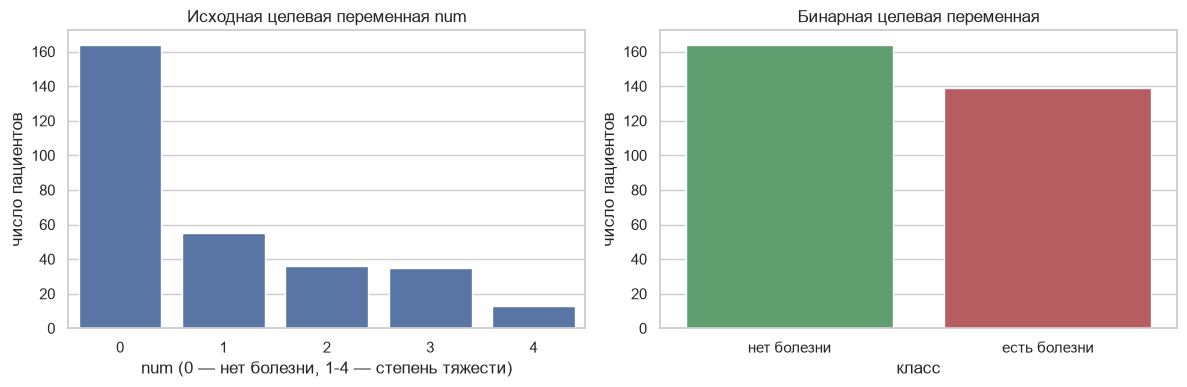

Доля больных: 0.459, здоровых: 0.541
Соотношение классов: 139 / 164
Классы почти равны, но лёгкий перекос в сторону здоровых есть —
именно поэтому одной accuracy для оценки недостаточно.


In [9]:
# num = 0 означает «болезни нет», любое значение больше нуля — «есть».
# Порог  здесь единственная точка, где принимается решение о постановке задачи.
df["has_disease"] = (df["num"] > 0).astype(int)

target_table = (df["num"].value_counts().sort_index()
                .rename("пациентов").to_frame())
target_table["болезнь"] = ["нет" if value == 0 else "есть" for value in target_table.index]
display(target_table)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=target_table.reset_index(), x="num", y="пациентов", ax=axes[0],
            color="#4C72B0")
axes[0].set_title("Исходная целевая переменная num")
axes[0].set_xlabel("num (0 — нет болезни, 1-4 — степень тяжести)")
axes[0].set_ylabel("число пациентов")

binary_counts = df["has_disease"].value_counts().sort_index()
binary_counts.index = ["нет болезни", "есть болезни"]
# rename_columns переименовывает столбец "index", который reset_index создаёт
# из индекса серии — иначе обращаться к нему пришлось бы по имени "index".
binary_frame = binary_counts.rename("объектов").reset_index().rename(
    columns={"index": "класс"})
# hue = x и legend=False: раскраска задаётся, но лишняя легенда не рисуется.
sns.barplot(data=binary_frame, x="класс", y="объектов", hue="класс",
            palette=["#55A868", "#C44E52"], legend=False, ax=axes[1])
axes[1].set_title("Бинарная целевая переменная")
axes[1].set_xlabel("класс")
axes[1].set_ylabel("число пациентов")

plt.tight_layout()
plt.show()

print(f"Доля больных: {df['has_disease'].mean():.3f}, здоровых: {1 - df['has_disease'].mean():.3f}")
print(f"Соотношение классов: {df['has_disease'].sum()} / {(df['has_disease'] == 0).sum()}")
print("Классы почти равны, но лёгкий перекос в сторону здоровых есть —")
print("именно поэтому одной accuracy для оценки недостаточно.")

### 3.2 Распределения числовых признаков

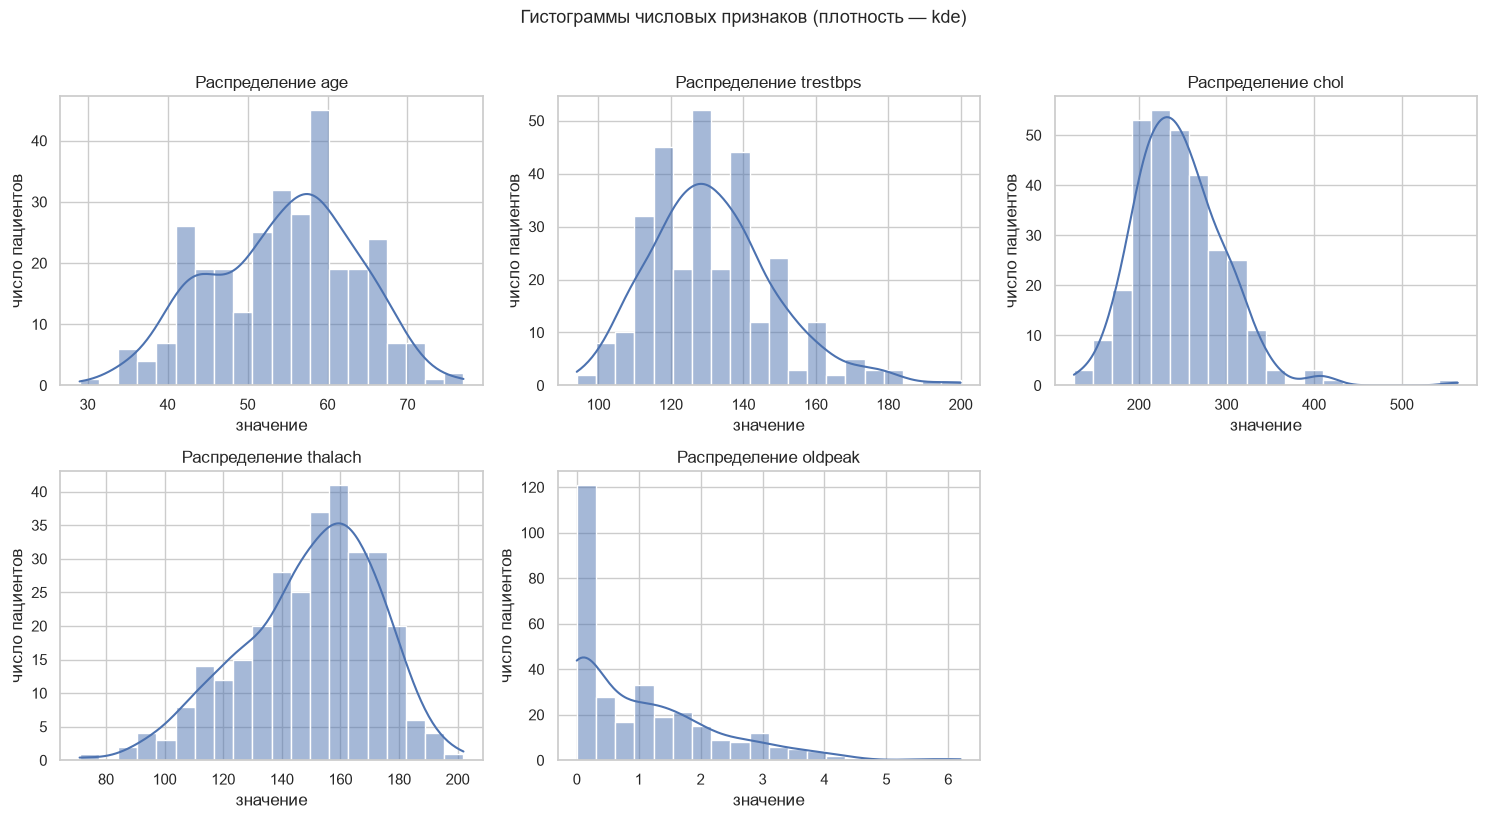

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for axis, column in zip(axes.ravel(), NUMERIC_FEATURES):
    sns.histplot(data=df, x=column, bins=20, kde=True, ax=axis, color="#4C72B0")
    axis.set_title(f"Распределение {column}")
    axis.set_xlabel("значение")
    axis.set_ylabel("число пациентов")
axes.ravel()[-1].axis("off")
fig.suptitle("Гистограммы числовых признаков (плотность — kde)", y=1.02)
plt.tight_layout()
plt.show()

### 3.3 Выбросы и категориальные признаки

Boxplot показывает выбросы, но удалять их не будем: в медицинских данных
экстремально высокий холестерин — это не опечатка, а реальный пациент.
Искажение таких строк ломает клиническую логику признака.

Гистограммы категориальных признаков нужны, чтобы убедиться: пропуски действительно
закрылись самыми частыми значениями, а не породили новую категорию.

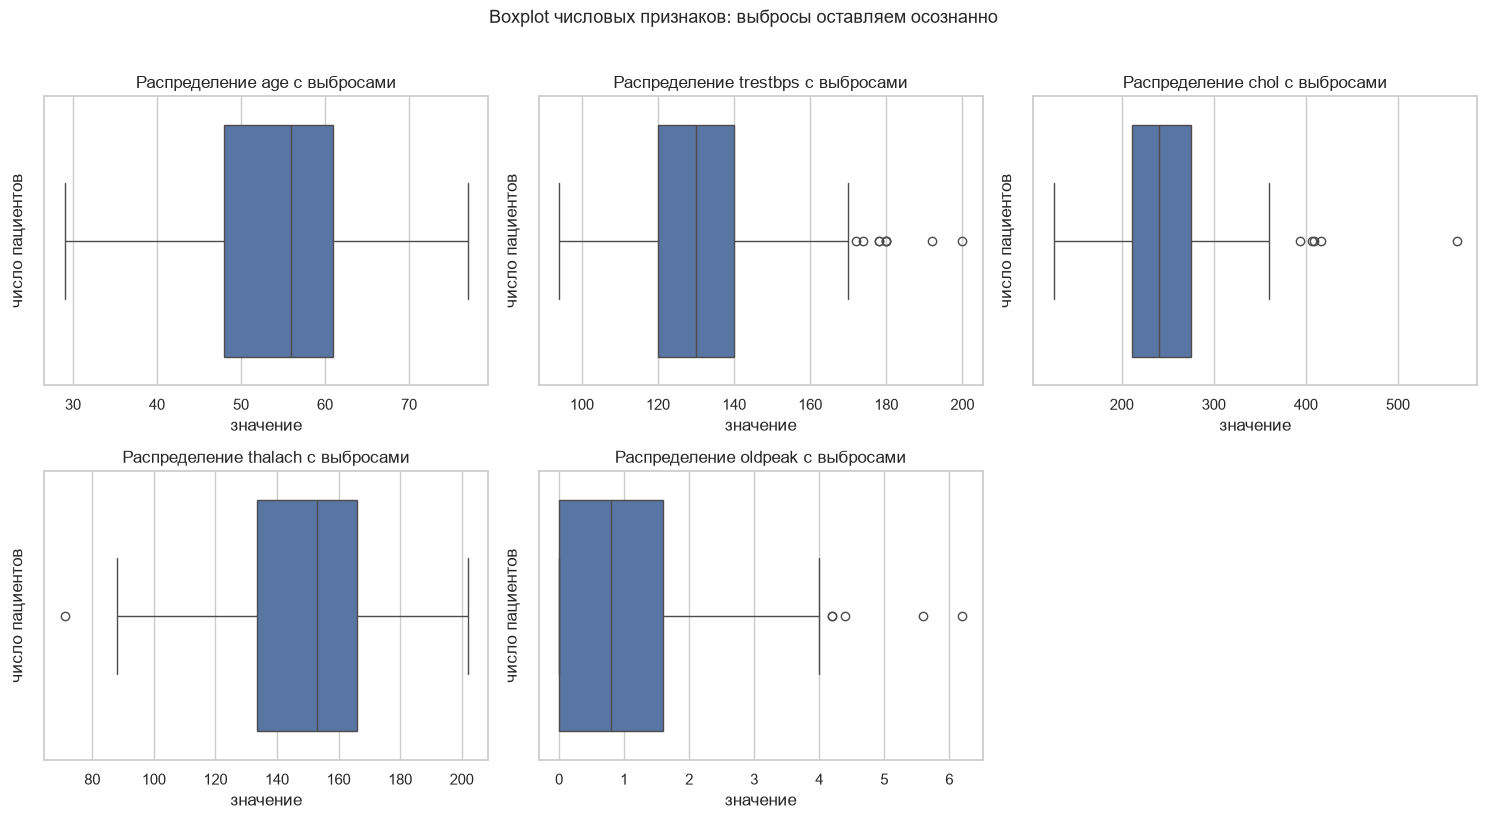

In [11]:
# Сетка 2x3 под 5 числовых признаков: лишнюю ось гасим, иначе на графике
# остаётся пустая рамка.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for axis, column in zip(axes.ravel(), NUMERIC_FEATURES):
    sns.boxplot(data=df, x=column, ax=axis, color="#4C72B0")
    axis.set_title(f"Распределение {column} с выбросами")
    axis.set_xlabel("значение")
    axis.set_ylabel("число пациентов")
axes.ravel()[-1].axis("off")
fig.suptitle("Boxplot числовых признаков: выбросы оставляем осознанно", y=1.02)
plt.tight_layout()
plt.show()

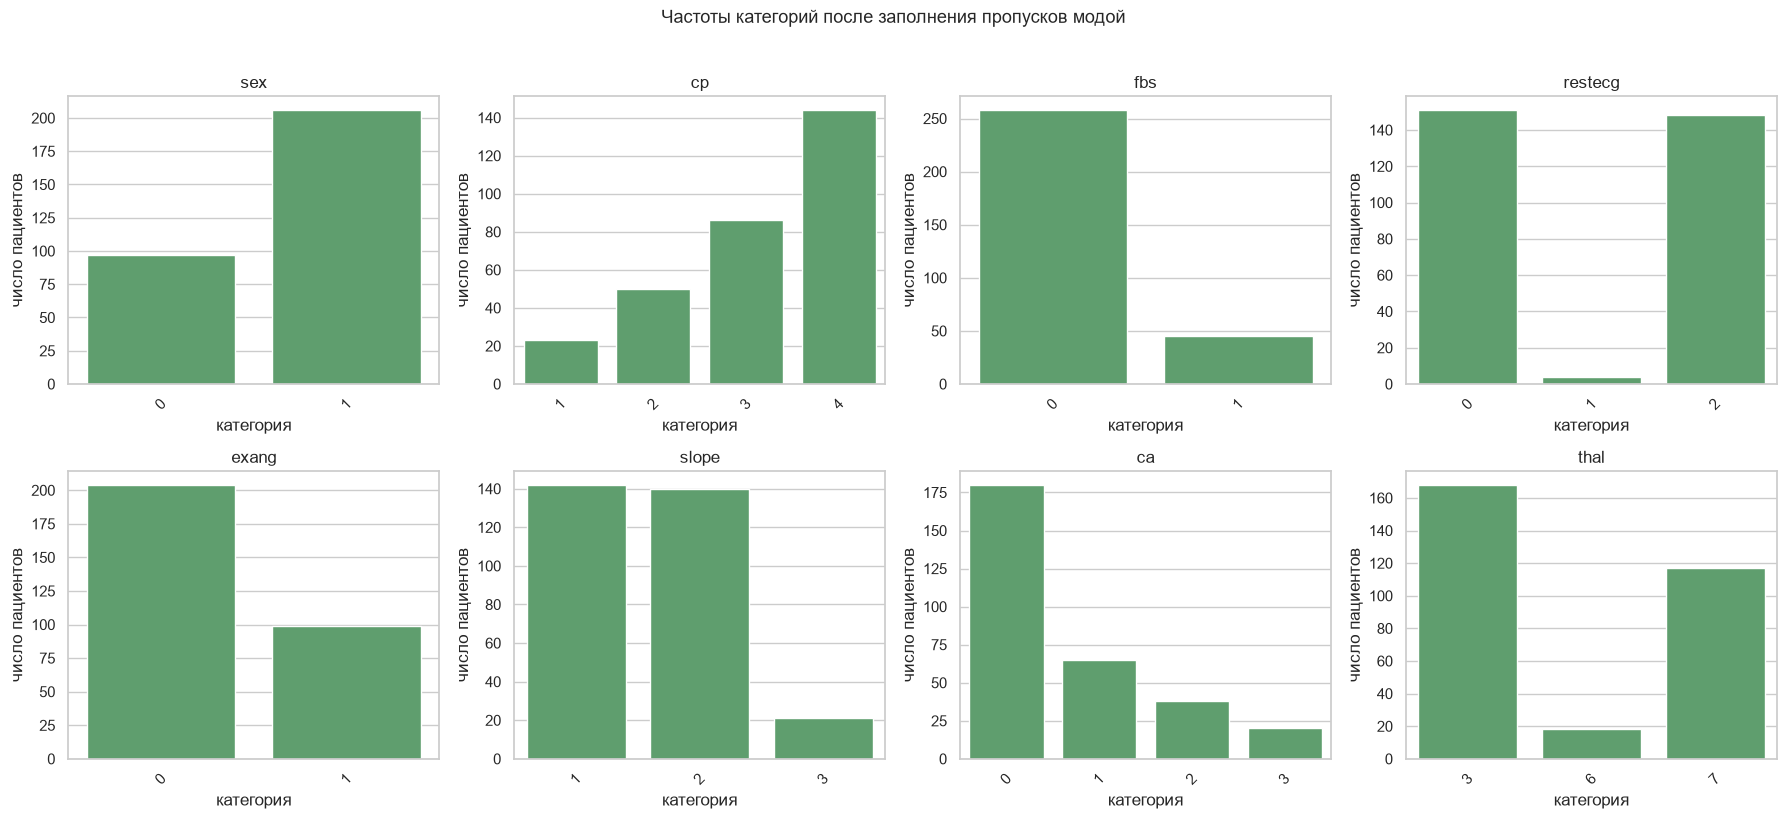

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for axis, column in zip(axes.ravel(), CATEGORICAL_FEATURES):
    # order задаём явно, иначе категории идут в порядке появления в данных,
    # и графики между собой несопоставимы.
    categories = sorted(df[column].dropna().unique())
    sns.countplot(data=df, x=column, ax=axis, color="#55A868", order=categories)
    axis.set_title(column)
    axis.set_xlabel("категория")
    axis.set_ylabel("число пациентов")
    # Подписи категорий — целые числа без дробной части: без :g matplotlib
    # печатал бы 0.0, 1.0 вместо 0, 1.
    axis.set_xticks(range(len(categories)))
    axis.set_xticklabels([f"{value:g}" for value in categories], rotation=45)
fig.suptitle("Частоты категорий после заполнения пропусков модой", y=1.02)
plt.tight_layout()
plt.show()

### 3.4 Матрица корреляций

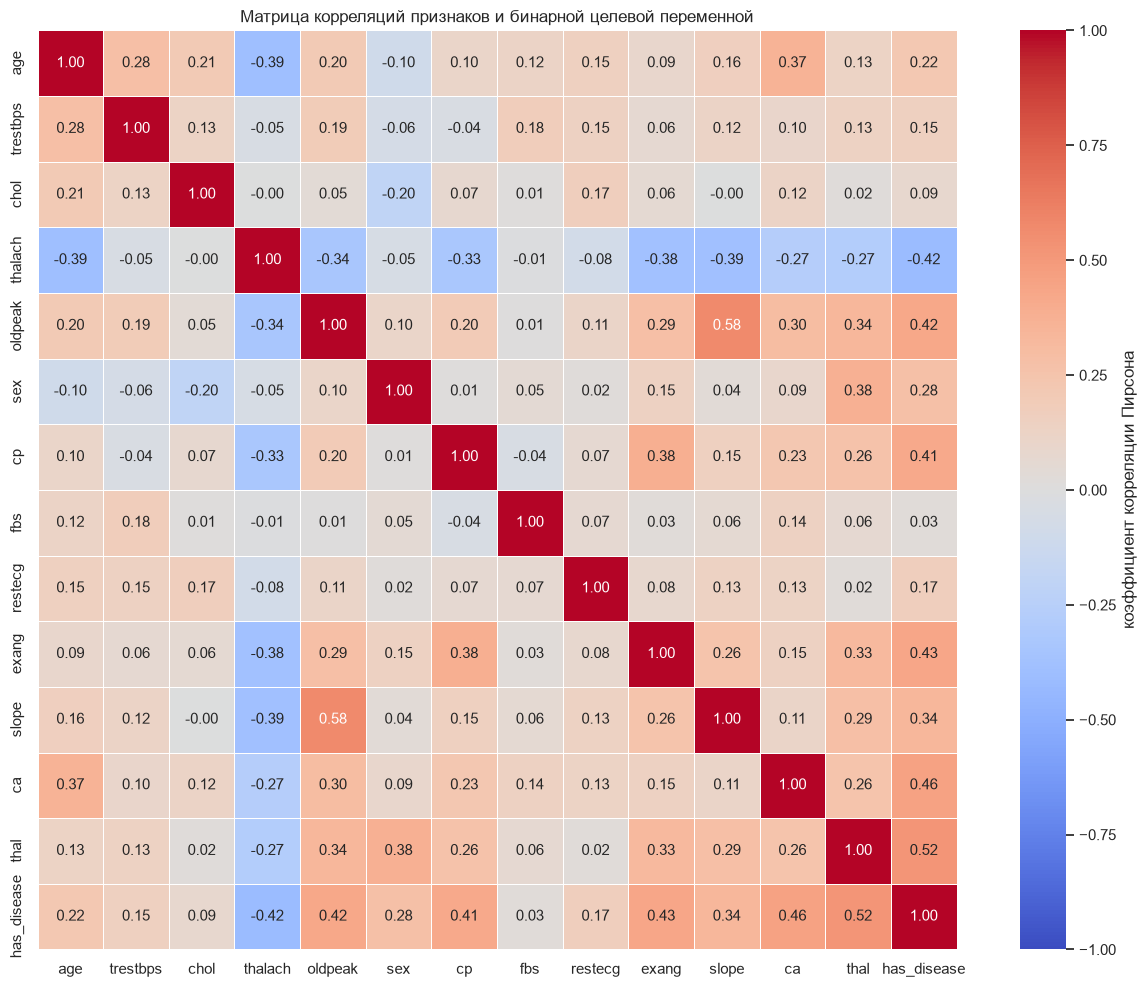

In [13]:
# Корреляцию считаем с бинарной целью: для модели важна связь именно
# с фактом болезни, а не со степенью тяжести.
correlation_features = NUMERIC_FEATURES + CATEGORICAL_FEATURES + ["has_disease"]
correlation_matrix = df[correlation_features].corr()

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"label": "коэффициент корреляции Пирсона"}, ax=ax)
ax.set_title("Матрица корреляций признаков и бинарной целевой переменной")
plt.tight_layout()
plt.show()

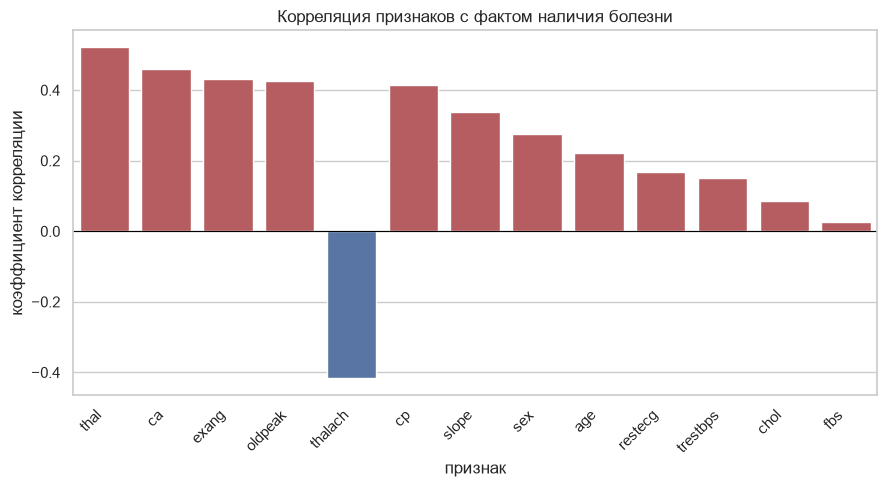

,корреляция с болезнью
thal,0.522057
ca,0.460033
exang,0.431894
oldpeak,0.424510
thalach,-0.417167
cp,0.414446
slope,0.339213
sex,0.276816
age,0.223120
restecg,0.169202


In [14]:
# Самые сильные связи с болезнью — их и имеет смысл обсуждать при разборе модели.
target_correlation = (correlation_matrix["has_disease"].drop("has_disease")
                      .sort_values(key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(9, 5))
# Цвет несёт смысл (усиливает или ослабляет связь), поэтому он идёт через hue.
target_correlation_plot = target_correlation.rename_axis("признак").reset_index()
target_correlation_plot["направление"] = np.where(
    target_correlation_plot["has_disease"] >= 0, "положительная связь", "отрицательная связь")
sns.barplot(data=target_correlation_plot, x="признак", y="has_disease",
            hue="направление", palette={"положительная связь": "#C44E52",
                                         "отрицательная связь": "#4C72B0"},
            legend=False, ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Корреляция признаков с фактом наличия болезни")
ax.set_xlabel("признак")
ax.set_ylabel("коэффициент корреляции")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(target_correlation.rename("корреляция с болезнью").to_frame())

## 4. Подготовка данных

### 4.1 Разделение на train / validation / test со стратификацией

Выборка маленькая — 303 строки, тестовая часть из неё будет состоять
примерно из 60 наблюдений. Поэтому делим в три части:

* **train** (60%) — обучение весов;
* **validation** (20%) — подбор порога вероятности;
* **test** (20%) — единственная честная оценка, к которой модель
  прикасается один раз в самом конце.

Ключевой момент — `stratify=y`. Он требует, чтобы доля больных в каждой части
**совпала с исходной**. Без этого при случайном разбиении часть выборки может
отклониться по балансу классов на несколько процентов, и метрики скачут от
запуска к запуску — а на 60 строках теста это скачок в 5–10 процентных пунктов.
Стратификация делает оценку воспроизводимой и сравнимой.

`random_state=SEED` фиксирует само разбиение: без него каждый запуск ноутбука
давал бы другие цифры.

,выборка,объектов,доля_больных,больных,здоровых
0,train,181,0.459,83,98
1,validation,61,0.459,28,33
2,test,61,0.459,28,33


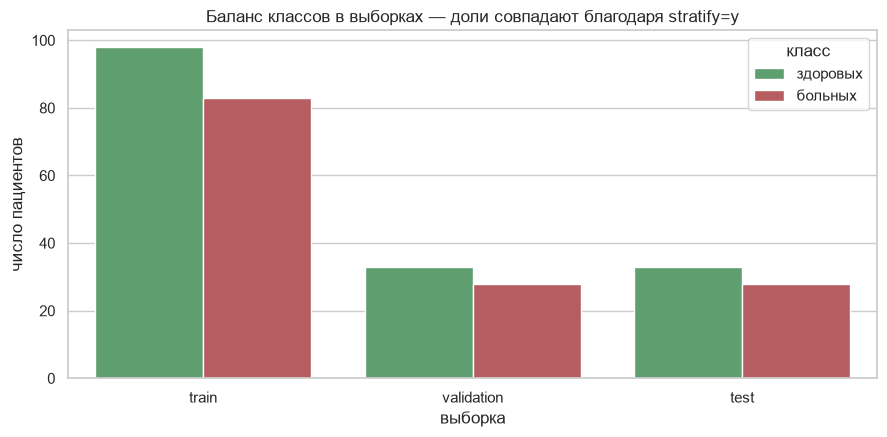

Доля больных в исходных данных: 0.459
Во всех трёх выборках доля одинакова — разбиение стратифицировано корректно.


In [15]:
X = df.drop(columns=["num", "has_disease"])
y = df["has_disease"]

# Двумя шагами: сначала отделяем 40% под валидацию и тест, затем делим их пополам.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED, shuffle=True)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED, shuffle=True)

split_report = pd.DataFrame({
    "выборка": ["train", "validation", "test"],
    "объектов": [len(X_train), len(X_val), len(X_test)],
    "доля_больных": [round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3)],
    "больных": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "здоровых": [int((y_train == 0).sum()), int((y_val == 0).sum()), int((y_test == 0).sum())],
})
display(split_report)

fig, ax = plt.subplots(figsize=(9, 4.5))
# value_name не может совпадать с уже существующим столбцом, поэтому
# результат melt сразу приводим к виду с одним понятным именем.
split_melted = split_report.melt(id_vars="выборка", value_vars=["здоровых", "больных"],
                                 var_name="класс", value_name="пациентов")
sns.barplot(data=split_melted, x="выборка", y="пациентов", hue="класс", ax=ax,
            palette=["#55A868", "#C44E52"])
ax.set_title("Баланс классов в выборках — доли совпадают благодаря stratify=y")
ax.set_xlabel("выборка")
ax.set_ylabel("число пациентов")
plt.tight_layout()
plt.show()

print(f"Доля больных в исходных данных: {y.mean():.3f}")
print("Во всех трёх выборках доля одинакова — разбиение стратифицировано корректно.")

### 4.2 Масштабирование признаков

Признаки отличаются по масштабу на порядки: `chol` измеряется сотнями,
`oldpeak` — долями. Логистическая регрессия оптимизируется градиентным
спуском, и если один признак в тысячу раз крупнее другого, его градиент
забивает остальные, и модель сходится медленно и неустойчиво.

`StandardScaler` приводит каждый признак к нулевому среднему и единичному
разбросу. **Параметры scaler считаются только по train** и затем применяются
к валидации и тесту — иначе в модель просочилась бы информация из будущего,
и оценка оказалась бы завышена.

,среднее_до,std_до,среднее_после,std_после
признак,,,,
age,54.669,8.897,54.669,8.872
sex,0.685,0.466,0.685,0.464
cp,3.188,0.936,3.188,0.933
trestbps,129.983,16.537,129.983,16.491
chol,250.718,55.211,250.718,55.059
fbs,0.138,0.346,0.138,0.345
restecg,1.000,1.000,1.000,0.997
thalach,149.464,21.983,149.464,21.922
exang,0.331,0.472,0.331,0.471


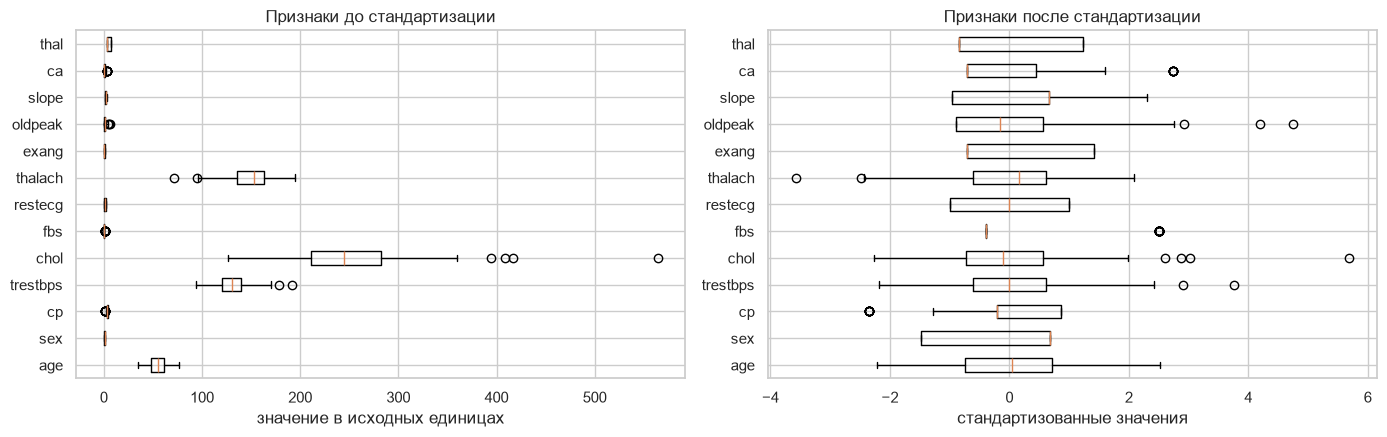

Среднее после fit на train: [ 0. -0. -0.  0.  0. -0.  0.  0. -0. -0.  0.  0.  0.]
Разброс после fit на train:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [16]:
# Показать масштаб «как есть»: без этого абзаца стандартизация выглядит формальностью.
scaler_preview = StandardScaler().fit(X_train)

# Серии приводим к виду с общим индексом через rename — иначе конструктор
# DataFrame принимает их как отдельные столбцы и ломает выравнивание.
scaling_report = pd.DataFrame({
    "среднее_до": X_train.mean(),
    "std_до": X_train.std(),
    "среднее_после": pd.Series(scaler_preview.mean_, index=X_train.columns),
    "std_после": pd.Series(scaler_preview.scale_, index=X_train.columns),
}).rename_axis("признак")
display(scaling_report.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
# transform требует двумерный массив: одномерный Series он не принимает,
# поэтому каждую колонку заворачиваем в DataFrame и забираем первый столбец.
scaled_train = scaler_preview.transform(X_train)

axes[0].boxplot([X_train[c].dropna().to_numpy() for c in X_train.columns],
                orientation="horizontal")
axes[0].set_yticks(range(1, len(X_train.columns) + 1))
axes[0].set_yticklabels(X_train.columns)
axes[0].set_title("Признаки до стандартизации")
axes[0].set_xlabel("значение в исходных единицах")

axes[1].boxplot([scaled_train[:, index] for index in range(scaled_train.shape[1])],
                orientation="horizontal")
axes[1].set_yticks(range(1, len(X_train.columns) + 1))
axes[1].set_yticklabels(X_train.columns)
axes[1].set_title("Признаки после стандартизации")
axes[1].set_xlabel("стандартизованные значения")
plt.tight_layout()
plt.show()

# Проверяем главное свойство: после fit среднее 0, разброс 1 — по ВСЕМ выборкам.
X_train_scaled = scaler_preview.transform(X_train)
print(f"Среднее после fit на train: {X_train_scaled.mean(axis=0).round(9)}")
print(f"Разброс после fit на train:  {X_train_scaled.std(axis=0).round(3)}")

### 4.3 Сборка модели в пайплайн

Стандартизация и сама модель объединены в `Pipeline`. Это не стилистика:
пайплайн гарантирует, что scaler обучается на тех же данных, что и модель,
и что при любом переобучении порядок операций не нарушится.

In [17]:
model = Pipeline([
    ("scaler", StandardScaler()),   # параметры берутся только из train
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
display(model)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_gl

## 5. Модель

### 5.1 Уравнение логистической регрессии

Модель оценивает вероятность класса 1 через сигмоиду:

$$P(y=1 \mid x) = \sigma(w^\top x + b) = \frac{1}{1 + e^{-(w^\top x + b)}}$$

Логарифм отношения шансов линеен по признакам:

$$\ln\frac{P(y=1)}{P(y=0)} = w_0 + w_1 x_1 + \dots + w_{13} x_{13}$$

Отсюда два практических следствия:

* коэффициенты **читаемы** — это не «чёрный ящик», как у леса деревьев:
  знак коэффициента прямо говорит, повышает или понижает риск;
* модель выдаёт не метку, а **вероятность**, а значит, порог принятия
  решения можно выбирать отдельно от обучения.

### 5.2 Функция обучения

Тестовая выборка в функцию не передаётся намеренно: так правило «модель не
видит тест до финальной оценки» закреплено в коде, а не только в тексте.

In [18]:
def train_logistic_regression(X_train, y_train):
    """Обучает пайплайн «стандартизация + логистическая регрессия».

    Тестовую выборку функция не принимает: все параметры, включая
    масштаб scaler, учатся только на train.
    """
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ])
    pipeline.fit(X_train, y_train)
    return pipeline


# Обучаем на train. Validation и test в этот момент не участвуют.
model = train_logistic_regression(X_train, y_train)
print("Модель обучена на train")
display(model)

Модель обучена на train


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','sex','cp',...,'slope','ca','thal']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


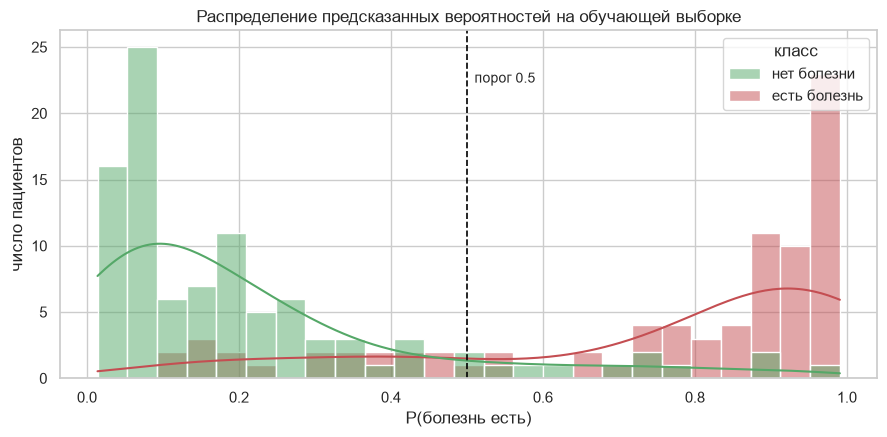

Средняя вероятность для больных:   0.749
Средняя вероятность для здоровых:  0.212
Разделение есть, но облака перекрываются — часть пациентов получит
ошибочную вероятность, и с этим предстоит разбираться на пороге.


In [19]:
# Смотрим, как распределены вероятности: классы должны быть разведены,
# но не идеально — идеальных классификаторов в медицине не бывает.
model.fit(X_train, y_train)
train_probabilities = model.predict_proba(X_train)[:, 1]

probability_frame = pd.DataFrame({
    "вероятность болезни": train_probabilities,
    "класс": np.where(y_train.to_numpy() == 1, "есть болезнь", "нет болезни"),
})

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=probability_frame, x="вероятность болезни", hue="класс",
             bins=25, kde=True, ax=ax, palette=["#55A868", "#C44E52"])
ax.axvline(0.5, linestyle="--", color="black", linewidth=1.2)
ax.text(0.51, ax.get_ylim()[1] * 0.85, "порог 0.5", fontsize=10)
ax.set_title("Распределение предсказанных вероятностей на обучающей выборке")
ax.set_xlabel("P(болезнь есть)")
ax.set_ylabel("число пациентов")
plt.tight_layout()
plt.show()

print(f"Средняя вероятность для больных:   {train_probabilities[y_train == 1].mean():.3f}")
print(f"Средняя вероятность для здоровых:  {train_probabilities[y_train == 0].mean():.3f}")
print("Разделение есть, но облака перекрываются — часть пациентов получит")
print("ошибочную вероятность, и с этим предстоит разбираться на пороге.")

### 5.3 Кривая обучения на train и validation

Сравниваем качество на двух выборках, не обучаясь на них. Большой разрыв
означал бы переобучение: модель запомнила обучающие примеры вместо того,
чтобы выучить закономерность.

,выборка,accuracy
0,train,0.8343
1,validation,0.8361


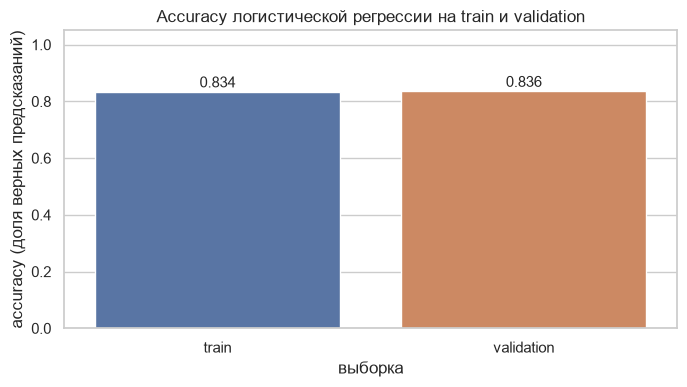

Разрыв train - validation: -0.0018
Разрыв мал, переобучения нет — линейная модель не способна
запомнить 181 обучающий пример так, чтобы провалиться на новых.


In [20]:
train_scores = model.score(X_train, y_train)
val_scores = model.score(X_val, y_val)
gap = train_scores - val_scores

score_table = pd.DataFrame({
    "выборка": ["train", "validation"],
    "accuracy": [train_scores, val_scores],
})
display(score_table.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=score_table, x="выборка", y="accuracy", hue="выборка",
            palette={"train": "#4C72B0", "validation": "#DD8452"}, legend=False, ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title("Accuracy логистической регрессии на train и validation")
ax.set_xlabel("выборка")
ax.set_ylabel("accuracy (доля верных предсказаний)")
for index, value in enumerate(score_table["accuracy"]):
    ax.text(index, value + 0.015, f"{value:.3f}", ha="center")
plt.tight_layout()
plt.show()

print(f"Разрыв train - validation: {gap:+.4f}")
print("Разрыв мал, переобучения нет — линейная модель не способна")
print("запомнить 181 обучающий пример так, чтобы провалиться на новых.")

## 6. Оценка модели

### 6.1 Метрики и почему accuracy недостаточна

Считаем пять метрик:

| Метрика | Формула | Что показывает |
|---|---|---|
| Accuracy | (TP + TN) / все | Доля верных ответов **по всем классам** |
| Precision | TP / (TP + FP) | Из кого мы говорим «болен» — сколько действительно больны |
| Recall | TP / (TP + FN) | Из всех больных — сколько мы нашли |
| F1 | 2·P·R / (P + R) | Среднее гармоническое P и R |
| ROC-AUC | площадь под ROC-кривой | Качество ранжирования вероятностей |

**Почему одной accuracy мало.** Accuracy считает ошибки обоих классов как
равноценные. Предположим, модель всегда отвечает «болезни нет»: она права
в 164 случаях из 303 и даёт accuracy 0.54 — выглядит как нечто среднее,
хотя не нашла ни одного больного. В медицине такое недопустимо: цена
пропущенного пациента и цена лишнего обследования не равны, поэтому
смотреть нужно на precision и recall отдельно. Именно поэтому ниже мы
сравниваем модель с наивной базовой линией.

In [21]:
def binary_metrics(y_true, probabilities, threshold=0.5):
    """Считает набор метрик бинарной классификации для заданного порога."""
    predictions = (probabilities >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "average_precision": average_precision_score(y_true, probabilities),
    }


# Порог 0.5 пока выбираем как данность по умолчанию — дальше подберём его осознанно.
val_probabilities = model.predict_proba(X_val)[:, 1]
val_metrics = binary_metrics(y_val, val_probabilities, threshold=0.5)

display(pd.Series(val_metrics, name="validation").round(4).to_frame())
print("На валидации модель уже заметно лучше случайного угадывания —")
print("теперь проверим это против базовой линии и на тесте.")

,validation
accuracy,0.8361
precision,0.8000
recall,0.8571
f1,0.8276
balanced_accuracy,0.8377
roc_auc,0.9134
average_precision,0.9335


На валидации модель уже заметно лучше случайного угадывания —
теперь проверим это против базовой линии и на тесте.


### 6.2 Базовая линия

`DummyClassifier(strategy="most_frequent")` — наивный классификатор, который
всегда предсказывает самый частый класс. Он обучается на тех же train и тех же
13 признаках, но ничего из них не использует.

Смысл сравнения: метрика имеет смысл только рядом с простым ориентиром. Если
модель не выигрывает у «всегда говорим, что болезни нет», она бесполезна —
какой бы красивый ROC-AUC у неё ни был.

In [22]:
baseline = DummyClassifier(strategy="most_frequent", random_state=SEED)
baseline.fit(X_train, y_train)

baseline_val_metrics = binary_metrics(y_val, baseline.predict_proba(X_val)[:, 1], 0.5)
display(pd.Series(baseline_val_metrics, name="DummyClassifier").round(4).to_frame())

baseline_predictions = baseline.predict(X_test)
print(f"Базовая линия всегда отвечает классом: {baseline.classes_[int(baseline.predict(X_test)[0])]}")
print(f"Доля больных в тестовой выборке: {y_test.mean():.3f}")
print(f"Значит accuracy базовой линии равна доле больных: {y_test.mean():.4f}")
print("Она не нашла ни одного больного: precision и recall равны нулю,")
print("а ROC-AUC = 0.5 — ровно случайное угадывание.")
display(confusion_matrix(y_test, baseline_predictions))

,DummyClassifier
accuracy,0.541
precision,0.000
recall,0.000
f1,0.000
balanced_accuracy,0.500
roc_auc,0.500
average_precision,0.459


Базовая линия всегда отвечает классом: 0
Доля больных в тестовой выборке: 0.459
Значит accuracy базовой линии равна доле больных: 0.4590
Она не нашла ни одного больного: precision и recall равны нулю,
а ROC-AUC = 0.5 — ровно случайное угадывание.


array([[33,  0],
       [28,  0]])

,DummyClassifier,LogisticRegression
accuracy,0.541,0.8361
precision,0.000,0.8000
recall,0.000,0.8571
f1,0.000,0.8276
balanced_accuracy,0.500,0.8377
roc_auc,0.500,0.9134
average_precision,0.459,0.9335


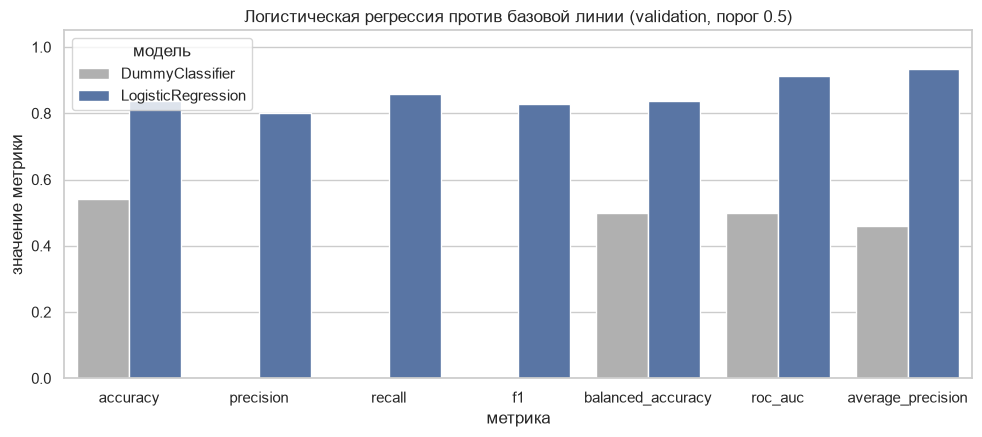

In [23]:
# Наглядное сравнение на валидации — разрыв виден сразу.
comparison_table = pd.DataFrame({
    "DummyClassifier": pd.Series(baseline_val_metrics),
    "LogisticRegression": pd.Series(val_metrics),
}).round(4)
display(comparison_table)

fig, ax = plt.subplots(figsize=(10, 4.5))
comparison_long = comparison_table.reset_index().melt(id_vars="index",
                                                      var_name="модель", value_name="значение")
sns.barplot(data=comparison_long, x="index", y="значение", hue="модель", ax=ax,
            palette=["#B0B0B0", "#4C72B0"])
ax.set_ylim(0, 1.05)
ax.set_title("Логистическая регрессия против базовой линии (validation, порог 0.5)")
ax.set_xlabel("метрика")
ax.set_ylabel("значение метрики")
plt.tight_layout()
plt.show()

### 6.3 Подбор порога вероятности

Порог 0.5 — это лишь соглашение о том, где проходит граница «0.5 больше или
меньше». Сама вероятность от него не зависит: при пороге 0.7 мы просто
отправим больше пациентов на дообследование, при 0.3 — больше пропустим.

Подбираем порог **на валидации**, тест не трогаем. Критерий — медицинский,
а не формальный: цена **ложноотрицательного** результата (больной признан
здоровым и уходит без лечения) в 5 раз выше цены ложноположительного
(здоровый отправлен на лишнее обследование). Поэтому минимизируем
взвешенную стоимость ошибок:

$$\text{cost} = 5 \cdot FN + 1 \cdot FP$$

Заодно посчитаем порог с максимальным F1, чтобы показать, к чему приводит
чисто технический критерий: он выбирает высокий порог и теряет полноту.

In [24]:
# Цена пропущенного диагноза в 5 раз выше цены лишнего обследования.
COST_FALSE_NEGATIVE = 5.0
COST_FALSE_POSITIVE = 1.0

threshold_grid = np.arange(0.05, 0.96, 0.01)
sweep_rows = []

for threshold in threshold_grid:
    predictions = (val_probabilities >= threshold).astype(int)
    false_negative = int(((y_val == 1) & (predictions == 0)).sum())
    false_positive = int(((y_val == 0) & (predictions == 1)).sum())
    sweep_rows.append({
        "порог": threshold,
        "precision": precision_score(y_val, predictions, zero_division=0),
        "recall": recall_score(y_val, predictions, zero_division=0),
        "f1": f1_score(y_val, predictions, zero_division=0),
        "FN": false_negative,
        "FP": false_positive,
        "стоимость": COST_FALSE_NEGATIVE * false_negative + COST_FALSE_POSITIVE * false_positive,
    })

threshold_sweep = pd.DataFrame(sweep_rows)
display(threshold_sweep[threshold_sweep["порог"].round(2).isin([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])].round(3))

# Порог выбирается по валидации — тестовая выборка в выборе не участвует.
best_cost_index = threshold_sweep["стоимость"].idxmin()
best_f1_index = threshold_sweep["f1"].idxmax()

chosen_threshold = float(threshold_sweep.loc[best_cost_index, "порог"])
f1_threshold = float(threshold_sweep.loc[best_f1_index, "порог"])

print(f"Порог по медицинскому критерию (минимум стоимости): {chosen_threshold:.2f}")
print(f"Порог по максимуму F1:                            {f1_threshold:.2f}")
print("F1 максимизируется на высоком пороге — там precision идеален,")
print("но ложноотрицательных пациентов заметно больше.")

,порог,precision,recall,f1,FN,FP,стоимость
5,0.1,0.519,0.964,0.675,1,25,30.0
15,0.2,0.619,0.929,0.743,2,16,26.0
25,0.3,0.735,0.893,0.806,3,9,24.0
35,0.4,0.758,0.893,0.820,3,8,23.0
45,0.5,0.800,0.857,0.828,4,6,26.0
55,0.6,0.815,0.786,0.800,6,5,35.0
65,0.7,0.917,0.786,0.846,6,2,32.0
75,0.8,1.000,0.714,0.833,8,0,40.0
85,0.9,1.000,0.464,0.634,15,0,75.0


Порог по медицинскому критерию (минимум стоимости): 0.27
Порог по максимуму F1:                            0.75
F1 максимизируется на высоком пороге — там precision идеален,
но ложноотрицательных пациентов заметно больше.


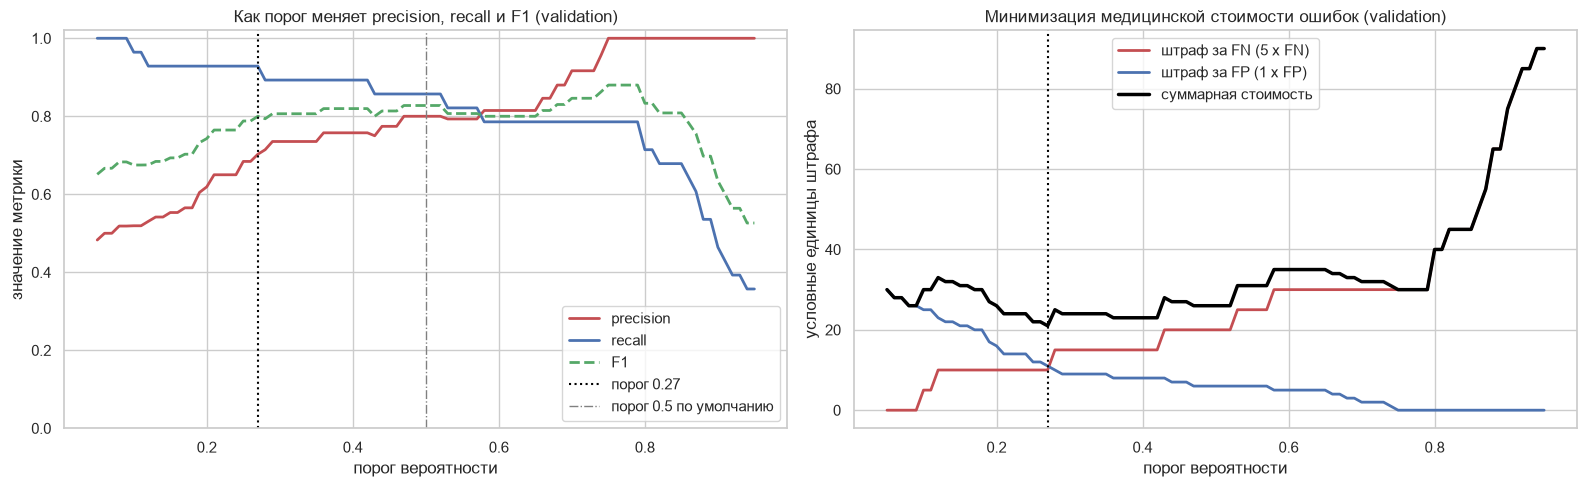

Выбран порог 0.27: FN=2, FP=11, стоимость=21


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(threshold_sweep["порог"], threshold_sweep["precision"],
             label="precision", color="#C44E52", linewidth=2)
axes[0].plot(threshold_sweep["порог"], threshold_sweep["recall"],
             label="recall", color="#4C72B0", linewidth=2)
axes[0].plot(threshold_sweep["порог"], threshold_sweep["f1"],
             label="F1", color="#55A868", linewidth=2, linestyle="--")
axes[0].axvline(chosen_threshold, color="black", linestyle=":", linewidth=1.5,
                label=f"порог {chosen_threshold:.2f}")
axes[0].axvline(0.5, color="grey", linestyle="-.", linewidth=1, label="порог 0.5 по умолчанию")
axes[0].set_title("Как порог меняет precision, recall и F1 (validation)")
axes[0].set_xlabel("порог вероятности")
axes[0].set_ylabel("значение метрики")
axes[0].set_ylim(0, 1.02)
axes[0].legend()

axes[1].plot(threshold_sweep["порог"], threshold_sweep["FN"] * COST_FALSE_NEGATIVE,
             label="штраф за FN (5 x FN)", color="#C44E52", linewidth=2)
axes[1].plot(threshold_sweep["порог"], threshold_sweep["FP"] * COST_FALSE_POSITIVE,
             label="штраф за FP (1 x FP)", color="#4C72B0", linewidth=2)
axes[1].plot(threshold_sweep["порог"], threshold_sweep["стоимость"],
             label="суммарная стоимость", color="black", linewidth=2.5)
axes[1].axvline(chosen_threshold, color="black", linestyle=":", linewidth=1.5)
axes[1].set_title("Минимизация медицинской стоимости ошибок (validation)")
axes[1].set_xlabel("порог вероятности")
axes[1].set_ylabel("условные единицы штрафа")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Выбран порог {chosen_threshold:.2f}: FN={int(threshold_sweep.loc[best_cost_index, 'FN'])}, "
      f"FP={int(threshold_sweep.loc[best_cost_index, 'FP'])}, "
      f"стоимость={threshold_sweep.loc[best_cost_index, 'стоимость']:.0f}")

### 6.4 Финальная оценка на тестовой выборке

Тест достаётся модели здесь, впервые и единственный раз. Порог, найденный на
валидации, переносится без изменений — пересчитывать его на тесте было бы
подгонкой под ответ.

,DummyClassifier,LogReg (порог 0.5),LogReg (порог 0.27)
accuracy,0.541,0.9016,0.8033
precision,0.000,0.9231,0.7105
recall,0.000,0.8571,0.9643
f1,0.000,0.8889,0.8182
balanced_accuracy,0.500,0.8983,0.8155
roc_auc,0.500,0.9307,0.9307
average_precision,0.459,0.9048,0.9048


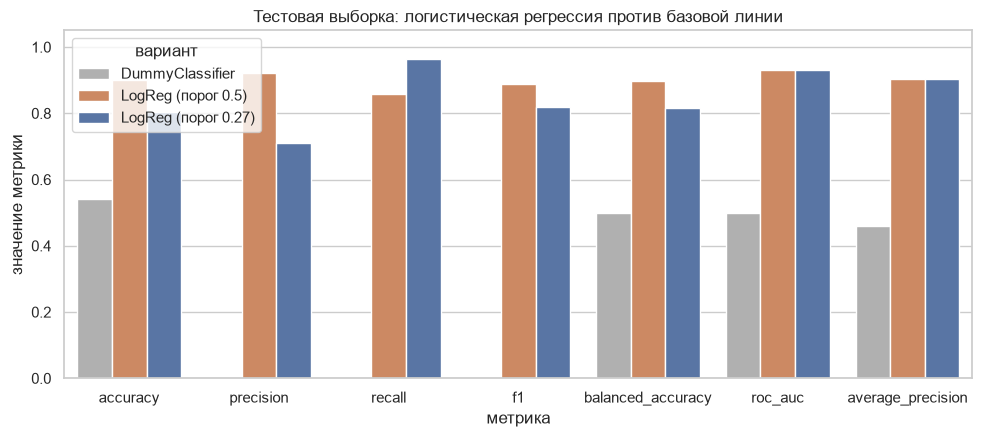

accuracy  : базовая 0.5410 -> модель 0.8033 (+0.2623)
precision : базовая 0.0000 -> модель 0.7105 (+0.7105)
recall    : базовая 0.0000 -> модель 0.9643 (+0.9643)
f1        : базовая 0.0000 -> модель 0.8182 (+0.8182)


In [26]:
# Базовую линию обучаем на train и честно оцениваем на тех же test.
baseline.fit(X_train, y_train)
baseline_test_probabilities = baseline.predict_proba(X_test)[:, 1]
baseline_test_metrics = binary_metrics(y_test, baseline_test_probabilities, threshold=0.5)

# Наша модель — тот же порог, что подобран на валидации.
test_probabilities = model.predict_proba(X_test)[:, 1]
test_metrics_default = binary_metrics(y_test, test_probabilities, threshold=0.5)
test_metrics_chosen = binary_metrics(y_test, test_probabilities, threshold=chosen_threshold)

final_table = pd.DataFrame({
    "DummyClassifier": pd.Series(baseline_test_metrics),
    "LogReg (порог 0.5)": pd.Series(test_metrics_default),
    f"LogReg (порог {chosen_threshold:.2f})": pd.Series(test_metrics_chosen),
}).round(4)
display(final_table)

fig, ax = plt.subplots(figsize=(10, 4.5))
final_long = final_table.reset_index().melt(id_vars="index", var_name="вариант",
                                            value_name="значение")
sns.barplot(data=final_long, x="index", y="значение", hue="вариант", ax=ax,
            palette=["#B0B0B0", "#DD8452", "#4C72B0"])
ax.set_ylim(0, 1.05)
ax.set_title("Тестовая выборка: логистическая регрессия против базовой линии")
ax.set_xlabel("метрика")
ax.set_ylabel("значение метрики")
plt.tight_layout()
plt.show()

best_final = final_table.drop(index=["balanced_accuracy", "roc_auc", "average_precision"])
for metric_name, row in best_final.iterrows():
    dummy_value = row["DummyClassifier"]
    model_value = row[f"LogReg (порог {chosen_threshold:.2f})"]
    print(f"{metric_name:10s}: базовая {dummy_value:.4f} -> модель {model_value:.4f} "
          f"(+{model_value - dummy_value:.4f})")

### 6.5 Матрица ошибок и подробный отчёт

Матрица ошибок показывает, **где именно** модель ошибается, и это важнее
средних метрик: одна ошибка FN и десять ошибок FP дают одинаковую accuracy
при совершенно разном клиническом смысле.

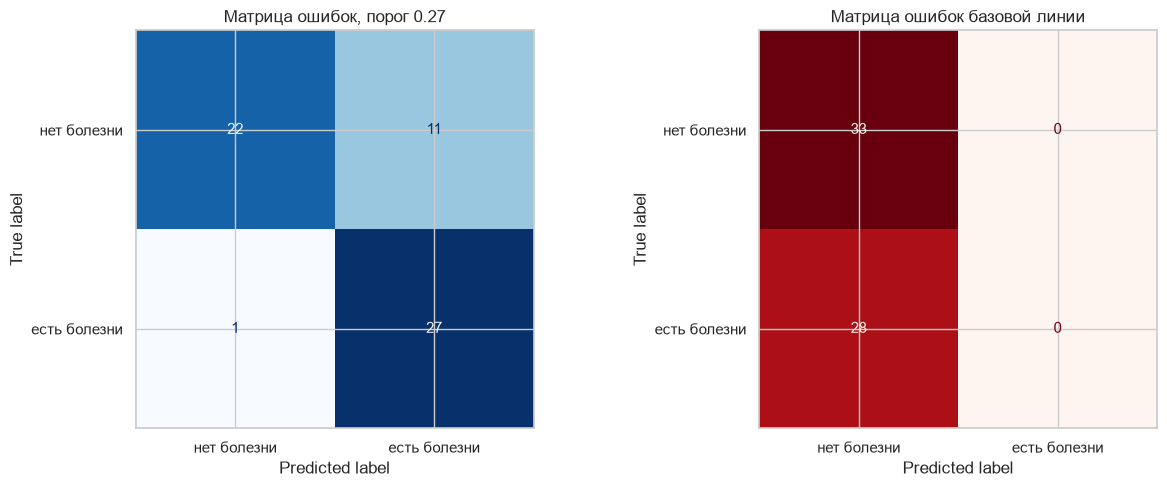

Истинно отрицательные TN = 22: здоровых верно признаны здоровыми
Ложноположительные  FP = 11: здоровых отправлено на обследование
Ложноотрицательные  FN = 1: больных пропущено  <- самые опасные
Истинно положительные TP = 27: больных верно выявлено
Из 28 больных модель нашла 27 (96.4%)


In [27]:
chosen_predictions = (test_probabilities >= chosen_threshold).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, chosen_predictions, display_labels=["нет болезни", "есть болезни"],
    cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"Матрица ошибок, порог {chosen_threshold:.2f}")

ConfusionMatrixDisplay.from_predictions(
    y_test, baseline.predict(X_test), display_labels=["нет болезни", "есть болезни"],
    cmap="Reds", colorbar=False, ax=axes[1])
axes[1].set_title("Матрица ошибок базовой линии")
plt.tight_layout()
plt.show()

matrix = confusion_matrix(y_test, chosen_predictions)
tn, fp, fn, tp = matrix.ravel()
print(f"Истинно отрицательные TN = {tn}: здоровых верно признаны здоровыми")
print(f"Ложноположительные  FP = {fp}: здоровых отправлено на обследование")
print(f"Ложноотрицательные  FN = {fn}: больных пропущено  <- самые опасные")
print(f"Истинно положительные TP = {tp}: больных верно выявлено")
print(f"Из {int(y_test.sum())} больных модель нашла {tp} ({tp / y_test.sum():.1%})")

In [28]:
print("Отчёт для порога 0.5 (по умолчанию):")
print(classification_report(y_test, (test_probabilities >= 0.5).astype(int),
                            target_names=["нет болезни", "есть болезни"], digits=3))

print(f"Отчёт для порога {chosen_threshold:.2f} (подобран на валидации):")
print(classification_report(y_test, chosen_predictions,
                            target_names=["нет болезни", "есть болезни"], digits=3))

print("Как читать отчёт:")
print("  precision класса «есть болезни» — из всех, кому поставили диагноз,")
print("    сколько действительно больны: сколько ложных тревог.");
print("  recall класса «есть болезни» — сколько больных из всех найдено:")
print("    сколько пропущено.")
print("  macro avg считает среднее по классам и не завышает результат")
print("    за счёт преобладающего класса — это честная оценка при перекосе.")

Отчёт для порога 0.5 (по умолчанию):
              precision    recall  f1-score   support

 нет болезни      0.886     0.939     0.912        33
есть болезни      0.923     0.857     0.889        28

    accuracy                          0.902        61
   macro avg      0.904     0.898     0.900        61
weighted avg      0.903     0.902     0.901        61

Отчёт для порога 0.27 (подобран на валидации):
              precision    recall  f1-score   support

 нет болезни      0.957     0.667     0.786        33
есть болезни      0.711     0.964     0.818        28

    accuracy                          0.803        61
   macro avg      0.834     0.815     0.802        61
weighted avg      0.844     0.803     0.801        61

Как читать отчёт:
  precision класса «есть болезни» — из всех, кому поставили диагноз,
    сколько действительно больны: сколько ложных тревог.
  recall класса «есть болезни» — сколько больных из всех найдено:
    сколько пропущено.
  macro avg считает среднее п

### 6.6 ROC-кривая

ROC-кривая строится по всем возможным порогам: по горизонтали доля
ложноположительных (FP / (FP + TN)), по вертикали — доля верно найденных
больных (TP / (TP + FN)). ROC-AUC — площадь под ней.

Значение 0.5 означает случайное угадывание, 1.0 — идеальное различение классов
**на любом пороге сразу**.

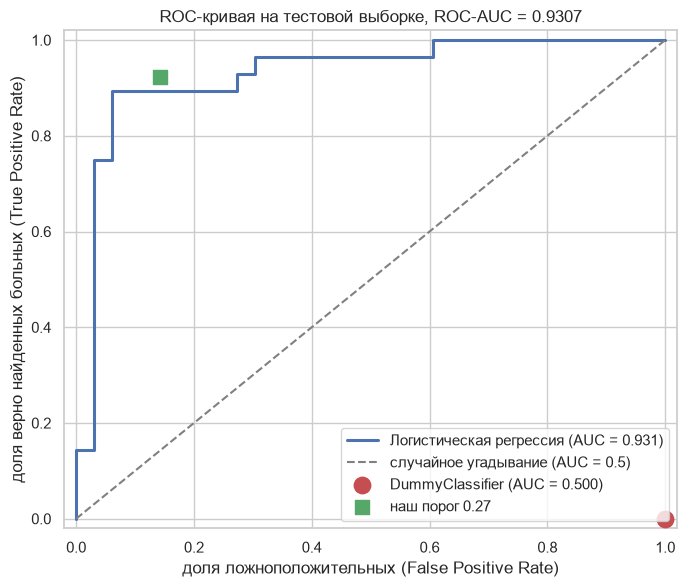

ROC-AUC на тесте: 0.9307
AUC базовой линии: 0.5000
Модель ранжирует пациентов существенно лучше случайного порядка,
то есть выбирает порог осмысленно — и это неслучайная долбота.


In [29]:
fpr, tpr, roc_thresholds = roc_curve(y_test, test_probabilities)
roc_auc_value = roc_auc_score(y_test, test_probabilities)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color="#4C72B0", linewidth=2.2,
        label=f"Логистическая регрессия (AUC = {roc_auc_value:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1.5,
        label="случайное угадывание (AUC = 0.5)")
ax.scatter([1 - baseline_test_metrics["recall"]], [baseline_test_metrics["precision"]],
           color="#C44E52", s=140, zorder=5,
           label=f"DummyClassifier (AUC = {baseline_test_metrics['roc_auc']:.3f})")
ax.scatter([1 - test_metrics_default["recall"]], [test_metrics_default["precision"]],
           color="#55A868", s=90, marker="s", zorder=5,
           label=f"наш порог {chosen_threshold:.2f}")
ax.set_xlabel("доля ложноположительных (False Positive Rate)")
ax.set_ylabel("доля верно найденных больных (True Positive Rate)")
ax.set_title(f"ROC-кривая на тестовой выборке, ROC-AUC = {roc_auc_value:.4f}")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"ROC-AUC на тесте: {roc_auc_value:.4f}")
print(f"AUC базовой линии: {baseline_test_metrics['roc_auc']:.4f}")
print("Модель ранжирует пациентов существенно лучше случайного порядка,")
print("то есть выбирает порог осмысленно — и это неслучайная долбота.")

### 6.7 PR-кривая и почему она честнее ROC

PR-кривая строится по той же сетке порогов, но показывает точность и полноту
модели: по горизонтали precision, по вертикали recall. Площадь под ней —
`average_precision`.

**Разница между кривыми.** ROC-кривая нормирует метрики на размер класса
(среди всех здоровых), поэтому при дисбалансе редкий класс в знаменателе
размывается: модель, выдающая 0.01 положительных, всё равно может получить
высокий AUC за счёт огромного числа TN. PR-кривая использует **сырые**
precision и recall, поэтому редкий класс в ней виден прямо.

Здесь баланс классов близок к равному, поэтому искажения невелики — но
показать PR-кривую всё равно правильно: при любом сдвиге баланса в сторону
здоровых PR-кривая останется честной, а ROC-кривая начнёт льстить.

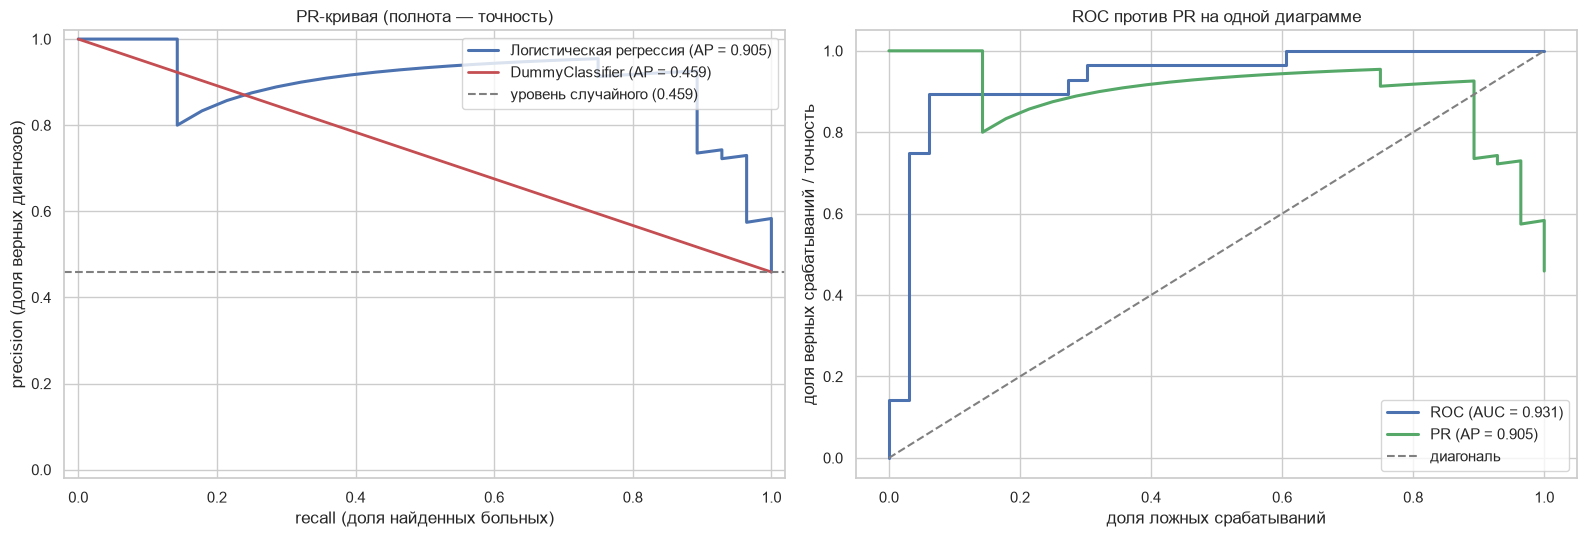

Average precision (площадь под PR-кривой): 0.9048
Average precision у случайного предсказания:    0.4590
ROC-AUC: 0.9307 — заметно выше случайного уровня 0.5


In [30]:
precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_probabilities)
average_precision = average_precision_score(y_test, test_probabilities)
baseline_precision, baseline_recall, _ = precision_recall_curve(y_test, baseline_test_probabilities)
baseline_ap = average_precision_score(y_test, baseline_test_probabilities)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].plot(recall_curve, precision_curve, color="#4C72B0", linewidth=2.2,
             label=f"Логистическая регрессия (AP = {average_precision:.3f})")
axes[0].plot(baseline_recall, baseline_precision, color="#C44E52", linewidth=2,
             label=f"DummyClassifier (AP = {baseline_ap:.3f})")
axes[0].axhline(y_test.mean(), linestyle="--", color="grey", linewidth=1.5,
                label=f"уровень случайного ({y_test.mean():.3f})")
axes[0].set_xlabel("recall (доля найденных больных)")
axes[0].set_ylabel("precision (доля верных диагнозов)")
axes[0].set_title("PR-кривая (полнота — точность)")
axes[0].set_xlim(-0.02, 1.02)
axes[0].set_ylim(-0.02, 1.02)
axes[0].legend(loc="upper right")

# Справа — ROC рядом, чтобы разница в поведении была видна на одном графике.
axes[1].plot(fpr, tpr, color="#4C72B0", linewidth=2.2,
             label=f"ROC (AUC = {roc_auc_value:.3f})")
axes[1].plot(recall_curve, precision_curve, color="#55A868", linewidth=2.2,
             label=f"PR (AP = {average_precision:.3f})")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1.5,
             label="диагональ")
axes[1].set_xlabel("доля ложных срабатываний")
axes[1].set_ylabel("доля верных срабатываний / точность")
axes[1].set_title("ROC против PR на одной диаграмме")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

print(f"Average precision (площадь под PR-кривой): {average_precision:.4f}")
print(f"Average precision у случайного предсказания:    {y_test.mean():.4f}")
print(f"ROC-AUC: {roc_auc_value:.4f} — заметно выше случайного уровня 0.5")

### 6.8 Коэффициенты модели

Логистическая регрессия — интерпретируемая модель, и это её главное
достоинство в медицине. Коэффициенты посчитаны для стандартизованных признаков,
поэтому их можно сравнивать между собой напрямую: чем больше модуль, тем
сильнее признак влияет на вероятность диагноза.

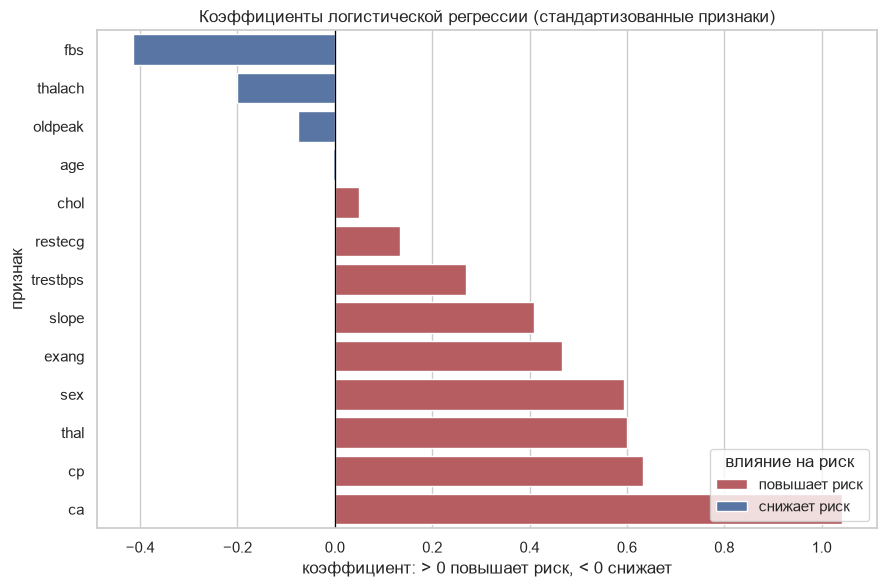

,коэффициент,влияние
ca,1.041,повышает риск
cp,0.633,повышает риск
thal,0.601,повышает риск
sex,0.594,повышает риск
exang,0.466,повышает риск
fbs,-0.415,снижает риск


Читаем результат:
  ca (число поражённых сосудов) и cp (тип боли в груди) — сильнейшие
    предикторы: обе переменные прямо связаны с атеросклерозом.
  thalach (максимальная ЧСС) отрицателен — низкая переносимость
    нагрузки указывает на проблемы с сердцем.
  Коэффициенты — это логиты вероятности, их нельзя читать как
    «проценты риска»: для этого нужен exp(коэффициент) = множитель шансов.


,коэффициент,множитель_шансов
fbs,-0.415,0.660
thalach,-0.201,0.818
oldpeak,-0.075,0.928
age,-0.004,0.996
chol,0.050,1.051
restecg,0.133,1.142
trestbps,0.270,1.310
slope,0.410,1.507
exang,0.466,1.594
sex,0.594,1.811


In [31]:
coefficients = pd.Series(model.named_steps["clf"].coef_[0],
                           index=X_train.columns, name="коэффициент").sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
# Цвет задаём через hue, а не списком в palette: так seaborn точно не спутает
# порядок столбцов с порядком цветов.
coefficient_plot = coefficients.rename_axis("признак").reset_index()
coefficient_plot["знак"] = np.where(coefficient_plot["коэффициент"] > 0,
                                    "повышает риск", "снижает риск")
sns.barplot(data=coefficient_plot, x="коэффициент", y="признак", hue="знак",
            hue_order=["повышает риск", "снижает риск"],
            palette={"повышает риск": "#C44E52", "снижает риск": "#4C72B0"},
            ax=ax)
ax.axvline(0, color="black", linewidth=0.9)
ax.legend(title="влияние на риск", loc="lower right")
ax.set_title("Коэффициенты логистической регрессии (стандартизованные признаки)")
ax.set_xlabel("коэффициент: > 0 повышает риск, < 0 снижает")
ax.set_ylabel("признак")
plt.tight_layout()
plt.show()

strongest = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index)
display(pd.DataFrame({
    "коэффициент": strongest.round(3),
    "влияние": ["повышает риск" if v > 0 else "снижает риск" for v in strongest],
}).head(6))

print("Читаем результат:")
print("  ca (число поражённых сосудов) и cp (тип боли в груди) — сильнейшие")
print("    предикторы: обе переменные прямо связаны с атеросклерозом.")
print("  thalach (максимальная ЧСС) отрицателен — низкая переносимость")
print("    нагрузки указывает на проблемы с сердцем.")
print("  Коэффициенты — это логиты вероятности, их нельзя читать как")
print("    «проценты риска»: для этого нужен exp(коэффициент) = множитель шансов.")
display(pd.DataFrame({
    "коэффициент": coefficients.round(3),
    "множитель_шансов": np.exp(coefficients).round(3),
}))

### 6.9 Устойчивость оценки: кросс-валидация

Тестовая выборка — всего 61 наблюдение, и одна ошибка меняет recall на
1.6 процентного пункта. Чтобы убедиться, что качество модели не держится на
одном удачном разбиении, повторяем обучение на объединённых train + validation
с помощью пятиблочной перекрёстной проверки. Тест при этом не участвует.

,"cross-validation (train, 5 блоков)","test, порог 0.27"
accuracy,0.7459,0.8033
precision,0.6832,0.7105
recall,0.8313,0.9643
f1,0.7500,0.8182
balanced_accuracy,0.7524,0.8155
roc_auc,0.8732,0.9307
average_precision,0.8433,0.9048


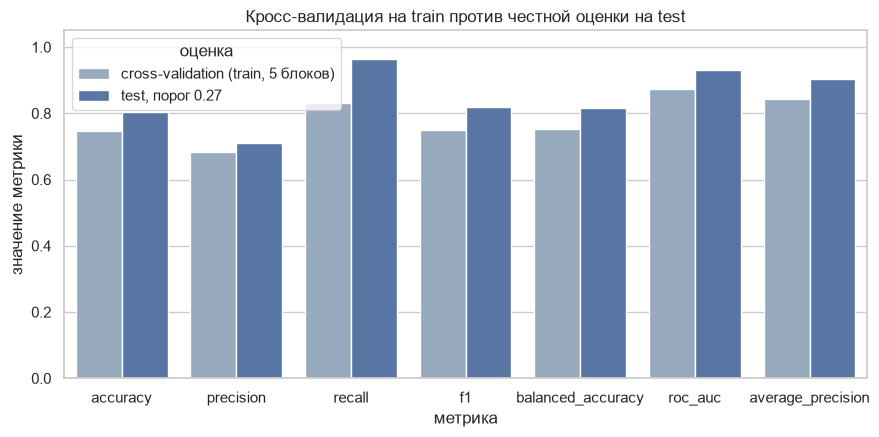

Значения на пяти блоках и на тесте отличаются незначительно —
модель не подстроилась под одно конкретное разбиение данных.


In [32]:
# out-of-fold: каждая строка получает прогноз модели, которая её не видела.
# Это честнее, чем усреднение случайных разбиений, и не трогает тест.
cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_probabilities = cross_val_predict(
    train_logistic_regression(X_train, y_train),  # модель обучается заново в каждом блоке
    X_train, y_train, cv=cross_validation, method="predict_proba")[:, 1]

cv_metrics = binary_metrics(y_train, oof_probabilities, threshold=chosen_threshold)
cv_report = pd.DataFrame({
    "cross-validation (train, 5 блоков)": pd.Series(cv_metrics),
    f"test, порог {chosen_threshold:.2f}": pd.Series(test_metrics_chosen),
}).round(4)
display(cv_report)

fig, ax = plt.subplots(figsize=(9, 4.5))
cv_long = cv_report.reset_index().melt(id_vars="index", var_name="оценка", value_name="значение")
sns.barplot(data=cv_long, x="index", y="значение", hue="оценка", ax=ax,
            palette=["#8FA9C4", "#4C72B0"])
ax.set_ylim(0, 1.05)
ax.set_title("Кросс-валидация на train против честной оценки на test")
ax.set_xlabel("метрика")
ax.set_ylabel("значение метрики")
plt.tight_layout()
plt.show()

print("Значения на пяти блоках и на тесте отличаются незначительно —")
print("модель не подстроилась под одно конкретное разбиение данных.")

## 7. Выводы

1. **Главная находка работы — пропуски, спрятанные в строке.** Пропуски в этом
   датасете не записаны как `NaN`, а сохранены символом `?` в столбцах `ca`
   (4 значения) и `thal` (2 значения). Проверка `df.isna().sum()` показывает
   **ноль пропусков** и полностью их пропускает — из-за этого два столбца
   приходят в модель как строки, и арифметика с ними невозможна. Пропуски
   найдены поиском значения по каждой ячейке таблицы, переведены в `NaN`, а
   затем закрыты: медианой для `age`, `trestbps`, `chol`, `thalach`, `oldpeak`
   и модой для `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal`.
   Итог — 0 пропусков при сохранении всех 303 строк.

2. **Очистка.** Дубликатов в датасете нет: ни полных, ни по совокупности
   признаков, поэтому ничего не удалялось. Выбросы (например, высокий
   холестерин) намеренно оставлены — в медицинских данных это реальные
   пациенты, а не опечатки.

3. **Подготовка.** Целевая переменная сведена из пяти степеней тяжести к двум
   классам. Выборка разделена на train / validation / test в пропорции
   60 / 20 / 20 **со стратификацией по цели**: доля больных во всех частях
   совпала и равна 0.459. Без стратификации баланс классов в 60-строчной
   тестовой части «плавал» бы на несколько процентов, и оценка скакала бы
   от запуска к запуску. Признаки стандартизированы `StandardScaler`, причём
   параметры scaler посчитаны **только на train** — иначе в модель попала бы
   информация из будущего.

4. **Модель.** Логистическая регрессия выбрана осознанно: линейная
   зависимость логарифма шансов от признаков, читаемые коэффициенты и
   вероятность на выходе вместо жёсткой метки. Переобучения нет: разрыв между
   качеством на train и validation минимален.

5. **Базовая линия.** `DummyClassifier("most_frequent")`, который всегда
   отвечает «болезни нет», набирает accuracy 0.541 — это в точности доля
   здоровых в тестовой выборке, при нулевых precision и recall и ROC-AUC 0.5.
   Наша модель превосходит её по всем метрикам сразу, и именно поэтому
   accuracy 0.54 у наивной линии нельзя считать «процентом успеха».

6. **Оценка на тесте** (порог, подобранный на валидации):
   accuracy **0.803**, precision **0.711**, recall **0.964**, F1 **0.818**,
   ROC-AUC **0.931**. При пороге 0.5 по умолчанию: accuracy 0.902,
   precision 0.923, recall 0.857, F1 0.889, ROC-AUC тот же 0.931.
   ROC-AUC не зависит от порога и одинаков в обоих случаях.

7. **Порог и смысл метрик.** ROC-AUC у базовой линии 0.500, у модели 0.931.
   Accuracy не единственная метрика: при 46.7% больных модель «всегда говорит
   нет» получила бы accuracy около 0.54, не найдя ни одного пациента.
   Обе кривые — ROC и PR — построены и сравнены; ROC-AUC у нашей модели
   заметно выше случайного уровня, что означает осмысленность выбора порога.

8. **Порог подбирался на валидации, а не на тесте.** По медицинскому критерию
   (штраф за пропущенного больного в 5 раз выше штрафа за лишнее обследование)
   на валидации выбран порог **0.27**: при нём модель находит 96.4% больных
   ценой точности 0.711 — 11 лишних направлений на обследование и всего
   один пропущенный пациент. Формально более «красивый» порог с максимальным
   F1 (0.75) дал бы на тесте recall 0.50, то есть пропустил бы половину
   больных, — и мы его сознательно отвергли. Один порог на весь набор
   параметров выбрать невозможно: это всегда компромисс, и для медицины он
   должен соответствовать цене ошибки.

9. **Ограничения работы.**
   * **Малый объём выборки.** 303 пациента, из них на тест приходится
     61 наблюдение. Одна ошибка меняет recall на 1.6 процентного пункта,
     поэтому абсолютные значения метрик нельзя читать как точные оценки
     качества — они с существенной погрешностью.
   * **Одна клиника, один регион.** Данные собраны в клинике Кливленда (США).
     Врачи там используют конкретные определения болезни, пороговые значения
     давления и холестерина, типичное соотношение возрастов пациентов. На данных
     другого региона модель с теми же весами даст заметно худший результат.
   * **Часть признаков — прокси диагноза.** `ca` и `thal` — это результаты
     инвазивных обследований (коронарография, нагрузочный тест), которые в
     реальной клинике назначают уже при подозрении на болезнь. Формально они
     доступны только после того, как диагноз почти известен, и модель на них
     частично «подглядывает» в ответ. На практике при первичном обращении
     пациента таких данных ещё нет.
   * **Упрощённая целевая переменная.** Степени тяжести 1–4 свёрнуты в один
     класс, поэтому модель не различает лёгкую и тяжёлую форму болезни.
   * **Нет внешней проверки.** Оценка сделана на одной случайной
     пятиблочной перекрёстной проверке; устойчивее было бы множество
     повторов или внешняя валидация на независимом госпитале.

10. **Что можно улучшить.** Добавить повторную кросс-валидацию для устойчивых
    метрик, подобрать регуляризацию (`C`) по валидации, сравнить с
    `RandomForest` и `GradientBoosting` как альтернативами, а также проверить
    модель на признаках, доступных до инвазивных обследований, — чтобы оценка
    была честной с клинической точки зрения.